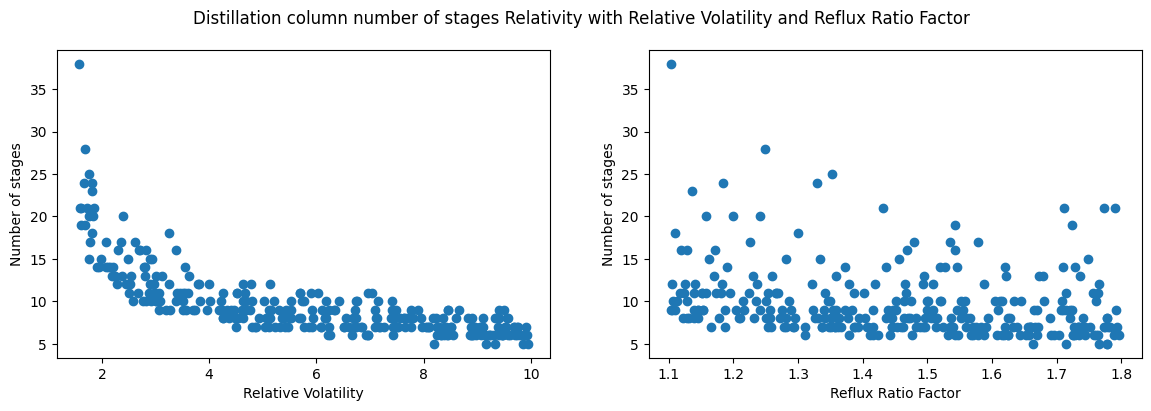

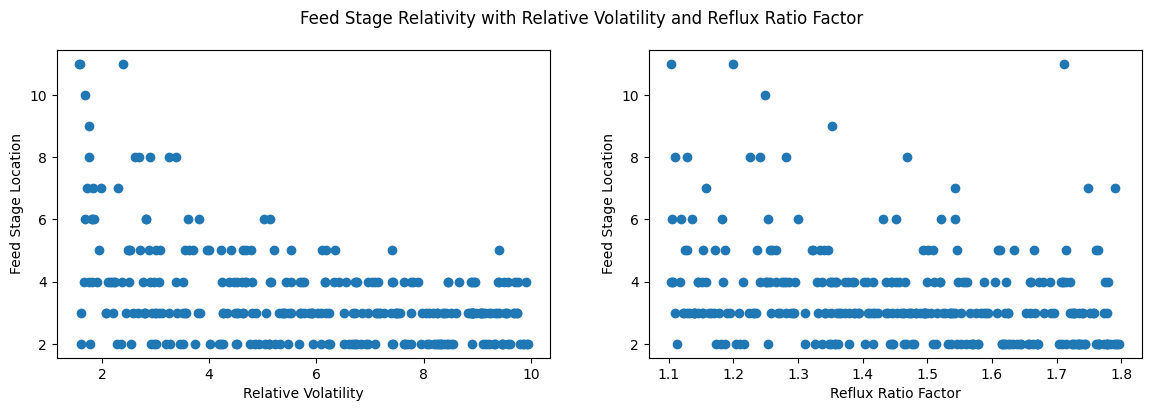

RMSE: 1.2522977233042243
R2: 0.7990210915932292


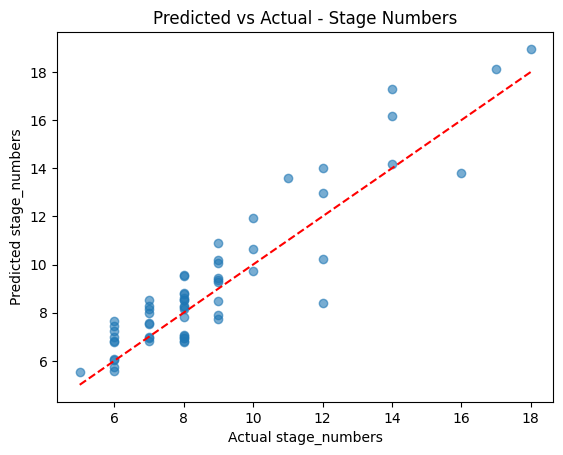

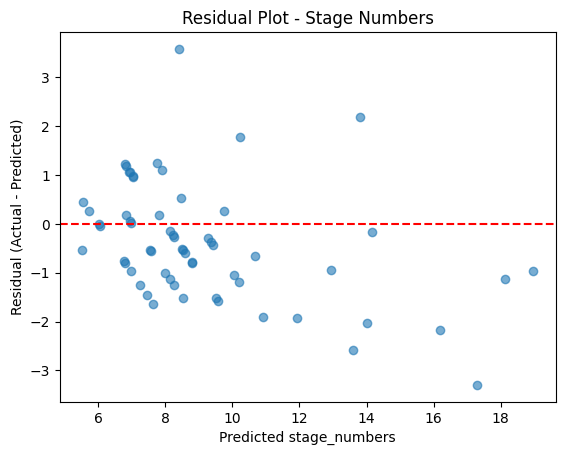

alpha: 0.777
R: 0.432
xF: -0.217
xD: 0.326
xB: -1.034
inv_R: 0.236
inv_alpha: 4.420
interactions: -0.069
RMSE: 0.7304041878051363
R2: 0.5731129141525204


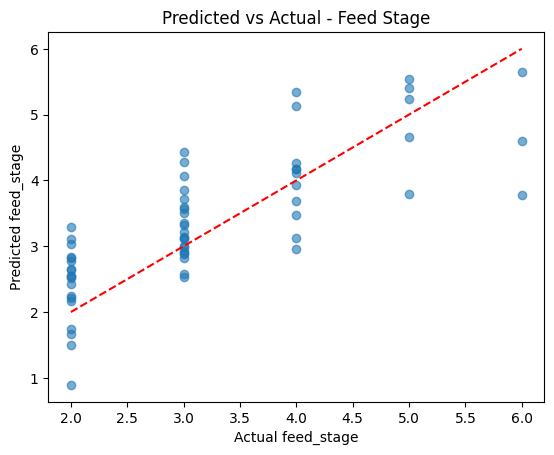

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
#equation for y_e equilibrium curve
def equilibrium_curve(x,alpha):
  y=alpha*x/(1+(alpha-1)*x)
  return y
  print(equilibrium_curve(0.5,4))

#equation for x_e equilibrium curve
def x_equilibrium_curve(y,alpha):
  x=y/(alpha-y*(alpha-1))
  return x
#rectifying line equation
def rectifying_line(x,R,xD):
  y=(R/(1+R))*x+xD/(R+1)
  return y
#stripping line equaion
def stripping_line(x, xB, x_intersect, y_intersect):
  slope=(y_intersect-xB)/(x_intersect-xB)
  y=slope*(x-xB)+xB
  return y
#calculating minimum reflux ratio encomposating the equilbrium curve formula for y
def calc_r_min(alpha,xF,xD):
  ye=equilibrium_curve(xF,alpha)
  r_min=(xD-ye)/(ye-xF)
  return r_min

def mccab_theile_method(alpha,R,xF,xD,xB,q):
  """McCabe Theile Method a technique to find the number of stages for distillation curve by knowing the relative volatility, Reflux ratio, composition of
  component in feed,distillate and bottom. This method also returns the feed stage location.
  """

  #intersection point for the line of striping, rectifying and feed line to change the line to find the number of stages through McCabe Theille graph
  if q==1:
    x_itersect=xF
    y_intersect=rectifying_line(xF,R,xD)
  if q!=1:
    slope_rect=R/(1+R)
    intercept_rect=xD/(1+R)
    slope_feed=q/(q-1)
    intercept_feed=-xF/(q-1)
    x_itersect= (intercept_feed-intercept_rect)/(slope_rect-slope_feed)
    y_intersect=rectifying_line(x_itersect,R,xD)

  x_current=xD
  y_current=xD

  stage_count=0
  feed_stage=None
  crossed_feed=False
  max_stage=100
  while x_current>xB and stage_count<= max_stage:
    #looping through to find the number of stages of column until the current compostion is less the the bottom composition and the number of stages is less than 100

    stage_count+=1
    x_current=x_equilibrium_curve(y_current,alpha)
    # checking that if the feed stage has reached or not
    if x_current<=x_itersect and not crossed_feed:
      feed_stage=stage_count
      crossed_feed =True
    #checking if the current composition is less than the bottom composition
    if x_current<xB:
      break
    #walking on the rectifyin line if feed stage is not reached else switching to the strippin line equation
    if not crossed_feed:

      y_current=rectifying_line(x_current,R,xD)
    else:
      y_current=stripping_line(x_current,xB,x_itersect,y_intersect)
  return stage_count,feed_stage

sample_size=300
data=[]
np.random.seed(42)
#for 300 sample size creating a dataframe for fixed relative volatility, Reflux ratio, feed compostion, distillate compostition, bottom composition, number of stages and feed stage location
for i in range(sample_size):
  alpha=np.random.uniform(1.5,10)
  xF=np.random.uniform(0.2,0.8)
  ye=equilibrium_curve(xF,alpha)
  if ye+0.01>=0.99:
    continue
  xD=np.random.uniform(ye+0.01,0.99)
  R_min=calc_r_min(alpha,xF,xD)
  r_factor=np.random.uniform(1.1,1.8)
  R=r_factor*R_min
  xB=np.random.uniform(0.001,0.05)
  stage_numbers,feed_stage=mccab_theile_method(alpha,R,xF,xD,xB,q=1)
  converged=stage_numbers<100
  data.append({
      "alpha":alpha,
      "R_min":R_min,
      "R_factor": r_factor,
      "R":R,
      "xF":xF,
      "xD":xD,
      "xB":xB,
      "stage_numbers":stage_numbers,
      "feed_stage":feed_stage,
      "converged":converged
  })
df=pd.DataFrame(data)
df["inv_R"]=1/df['R']
df["inv_alpha"]=1/df["alpha"]
df["interactions"]=df["inv_R"]*df["inv_alpha"]

#now creating the input features to X input numpy array
X=df[["alpha","R","xF","xD","xB","inv_R","inv_alpha","interactions"]].to_numpy()

#creating output feature of number of stages to y_stage_num
y_stage_num=df["stage_numbers"].to_numpy()

#creating output feature of feed stage location to y_feed_stage
y_feed_stage=df["feed_stage"].to_numpy()

#Visualizing Data for Number of Stages in the Distillation Column
fig,ax=plt.subplots(1,2,figsize=(14,4))
ax[0].scatter(df.alpha,y_stage_num)
ax[0].set_ylabel("Number of stages")
ax[0].set_xlabel("Relative Volatility")
ax[1].scatter(df.R_factor,df.stage_numbers)
ax[1].set_xlabel("Reflux Ratio Factor")
ax[1].set_ylabel("Number of stages")
plt.suptitle("Distillation column number of stages Relativity with Relative Volatility and Reflux Ratio Factor")
plt.show()

#Visualizing Data for Feed Stage Location
fig,ax=plt.subplots(1,2,figsize=(14,4))
ax[0].scatter(df.alpha,df.feed_stage)
ax[0].set_ylabel("Feed Stage Location")
ax[0].set_xlabel("Relative Volatility")
ax[1].scatter(df.R_factor,df.feed_stage)
ax[1].set_xlabel("Reflux Ratio Factor")
ax[1].set_ylabel("Feed Stage Location")
plt.suptitle("Feed Stage Relativity with Relative Volatility and Reflux Ratio Factor")
plt.show()

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression



"""Linear Regression for Model of Number of Stages"""
#spliting data for 80 to 20% of distribution for Number of Stages
X1_train,X1_test,y1_train,y1_test=train_test_split(X,y_stage_num,test_size=0.2,random_state=42)

#normalizing for number of stages
scalar=StandardScaler()
x1_norm=scalar.fit_transform(X1_train)

#creating model for linear regression for number of stages
model1=LinearRegression()

#training the model on the 80% of data that is training data
model1.fit(x1_norm,y1_train)

#finding parmaters for linear regression model for number of stages
w1=model1.coef_
b1=model1.intercept_

#normalizing the testing data for number of stages
x1_test_norm=scalar.transform(X1_test)

#now predicting for the test data for number of stage
y1_pred=model1.predict(x1_test_norm)

#calculating the mean square error for number of stages
MSE_num_stages=mean_squared_error(y1_pred,y1_test)

#calculating root mean square error for number of stages
RSME_num_stages=np.sqrt(MSE_num_stages)

#R square for the number of stages
R2_score_num_stages=r2_score(y1_test, y1_pred)

print("RMSE:", np.sqrt(mean_squared_error(y1_test, y1_pred)))
print("R2:", r2_score(y1_test, y1_pred))

#Visualizing the training and tested data for model of number of stages
plt.scatter(y1_test, y1_pred, alpha=0.6)
plt.plot([y1_test.min(), y1_test.max()], [y1_test.min(), y1_test.max()], 'r--')
plt.xlabel("Actual stage_numbers")
plt.ylabel("Predicted stage_numbers")
plt.title("Predicted vs Actual - Stage Numbers")
plt.show()

residuals = y1_test - y1_pred
plt.scatter(y1_pred, residuals, alpha=0.6)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel("Predicted stage_numbers")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot - Stage Numbers")
plt.show()

feature_names = ["alpha","R","xF","xD","xB","inv_R","inv_alpha","interactions"]
for name, coef in zip(feature_names, model1.coef_):
    print(f"{name}: {coef:.3f}")

"""Linear Regression For Feed Stage"""
#spliting data for 80 to 20% of distribution for feed stages
X2_train,X2_test,y2_train,y2_test=train_test_split(X,y_feed_stage,test_size=0.2,random_state=42)

#normalizing for feed stages
scalar=StandardScaler()
x2_norm=scalar.fit_transform(X2_train)

#creating model for linear regression for feed stages
model2=LinearRegression()
model2.fit(x2_norm,y2_train)
#finding parmaters for linear regression model for feed stages
w2=model2.coef_
b2=model2.intercept_

#normalizing the testing data for feed stages
x2_test_norm=scalar.transform(X2_test)

#now predicting for the test data for feed stages
y2_pred=model2.predict(x2_test_norm)

#calculating the mean square error for feed stages
MSE_num_stages=mean_squared_error(y2_pred,y2_test)

#calculating root mean square error for feed stages
RSME_num_stages=np.sqrt(MSE_num_stages)
#R square for feed stages
R2_score_num_stages=r2_score(y2_test, y2_pred)
print("RMSE:", np.sqrt(mean_squared_error(y2_test, y2_pred)))
print("R2:", r2_score(y2_test, y2_pred))
#data visulaization for feed stages Training model
plt.scatter(y2_test, y2_pred, alpha=0.6)
plt.plot([y2_test.min(), y2_test.max()], [y2_test.min(), y2_test.max()], 'r--')
plt.xlabel("Actual feed_stage")
plt.ylabel("Predicted feed_stage")
plt.title("Predicted vs Actual - Feed Stage")
plt.show()




In [3]:
df[['alpha','R','xF','xD','xB','stage_numbers','feed_stage']].corr()

,alpha,R,xF,xD,xB,stage_numbers,feed_stage
alpha,1.000000,-0.484802,-0.092988,0.314391,0.071265,-0.734831,-0.433842
R,-0.484802,1.000000,-0.213304,-0.028166,-0.063643,0.640631,0.719264
xF,-0.092988,-0.213304,1.000000,0.568228,0.014025,0.072503,0.069119
xD,0.314391,-0.028166,0.568228,1.000000,0.036151,-0.201774,0.301004
xB,0.071265,-0.063643,0.014025,0.036151,1.000000,-0.305964,-0.071057
stage_numbers,-0.734831,0.640631,0.072503,-0.201774,-0.305964,1.000000,0.690879
feed_stage,-0.433842,0.719264,0.069119,0.301004,-0.071057,0.690879,1.000000


In [5]:

test_df = pd.DataFrame(X1_test, columns=["alpha","R","xF","xD","xB","inv_R","inv_alpha","interactions"])
test_df["actual"] = y1_test
test_df["predicted"] = y1_pred
print(test_df[test_df.actual.isin([18,12])].sort_values("actual"))

       alpha         R        xF        xD        xB     inv_R  inv_alpha  \
15  2.978110  1.358438  0.437745  0.921985  0.008541  0.736140   0.335783   
39  4.781872  0.321069  0.776714  0.986526  0.004399  3.114597   0.209123   
57  2.498973  1.234877  0.589526  0.939740  0.048146  0.809797   0.400164   
59  5.130416  0.298476  0.690809  0.981610  0.026027  3.350350   0.194916   
11  1.805509  1.820119  0.479359  0.827361  0.029951  0.549415   0.553860   

    interactions  actual  predicted  
15      0.247184      12  14.021663  
39      0.651334      12  10.220324  
57      0.324052      12  12.953940  
59      0.653037      12   8.420189  
11      0.304299      18  18.968215  
